In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_olivetti_faces
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score as accuracy_metric
import matplotlib.pyplot as plt
from time import perf_counter
import joblib
from joblib import Parallel, delayed

C:\Users\gs070\AppData\Local\Temp\ipykernel_30544\2409633532.py:2: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


In [2]:
RANDOM_SEED=26005     # My roll no =M26MAC005
MAX_DEPTH_GRID=[2,4,8,16,None]
MIN_SAMPLES_LEAF_GRID=[1,2,4]
BAG_SIZE_VALUES = [1, 5, 10, 25, 50, 100, 200]

In [3]:
# Load data
data=fetch_olivetti_faces()
X_all=pd.DataFrame(data.data)
y_all=pd.DataFrame(data.target)

# Splitting the data as 6 images for training, 2 images for validation, and 2 images for testing for each subject
rng=np.random.default_rng(seed=RANDOM_SEED)
train_positions, val_positions, test_positions=[], [], []
for i in range(40):
    index= np.arange(i*10,(i+1)*10)
    rng.shuffle(index)

    train_positions.extend(index[:6])
    val_positions.extend(index[6:8])
    test_positions.extend(index[8:])

X_train_split,y_train_split =X_all.iloc[train_positions], y_all.iloc[train_positions]
X_val_split,y_val_split =X_all.iloc[val_positions], y_all.iloc[val_positions]
X_test_split,y_test_split =X_all.iloc[test_positions], y_all.iloc[test_positions]

In [4]:
# Saving training, validation and test sets to .npy files
np.savez('X_train.npy', X_train=X_train_split, y_train=y_train_split)
np.savez('X_val.npy', X_val=X_val_split, y_val=y_val_split)
np.savez('X_test.npy', X_test=X_test_split, y_test=y_test_split)

<h1>Ques-1</h1>
<h3>Decision tree baseline and bagging from scratch</h3>


In [5]:
# Part A
# Chechking the performance of DecisionTreeClassifier with different hyperparameters
single_tree_results=[]
single_tree_models={}
for depth in MAX_DEPTH_GRID:
    for min_samples in MIN_SAMPLES_LEAF_GRID:
        model=DecisionTreeClassifier(max_depth=depth, min_samples_leaf=min_samples, random_state=RANDOM_SEED)
        model.fit(X_train_split,y_train_split)

        leaf_ids = model.apply(X_train_split)    # Get the leaf node ids of the training samples
        _, counts = np.unique(leaf_ids, return_counts=True)    # Return the unique leaf node ids and their samples counts

        result={"max_depth": "None" if depth is None else depth,
                "min_samples_leaf": min_samples,

                "train_accuracy": accuracy_metric(y_train_split, model.predict(X_train_split)),
                "validation_accuracy": accuracy_metric(y_val_split, model.predict(X_val_split)),
                "test_accuracy": accuracy_metric(y_test_split, model.predict(X_test_split)),

                "leaves": int(len(counts)),
                "mean_samples_per_leaf": float(np.mean(counts)),
                "fraction_single_sample_leaves": float(np.mean(counts == 1)),

                }
        single_tree_results.append(result)
        single_tree_models[(depth, min_samples)] = model

selected_params = max(single_tree_results, key= lambda x: x["validation_accuracy"])
chosen_depth = None if selected_params["max_depth"] == "None" else int(selected_params["max_depth"])
chosen_leaf = int(selected_params["min_samples_leaf"])
chosen_model = single_tree_models[(chosen_depth, chosen_leaf)]
print(chosen_depth,chosen_leaf)

None 1


In [6]:
single_tree_results

[{'max_depth': 2,
  'min_samples_leaf': 1,
  'train_accuracy': 0.075,
  'validation_accuracy': 0.0625,
  'test_accuracy': 0.05,
  'leaves': 3,
  'mean_samples_per_leaf': 80.0,
  'fraction_single_sample_leaves': 0.0},
 {'max_depth': 2,
  'min_samples_leaf': 2,
  'train_accuracy': 0.075,
  'validation_accuracy': 0.0625,
  'test_accuracy': 0.05,
  'leaves': 3,
  'mean_samples_per_leaf': 80.0,
  'fraction_single_sample_leaves': 0.0},
 {'max_depth': 2,
  'min_samples_leaf': 4,
  'train_accuracy': 0.075,
  'validation_accuracy': 0.0625,
  'test_accuracy': 0.05,
  'leaves': 3,
  'mean_samples_per_leaf': 80.0,
  'fraction_single_sample_leaves': 0.0},
 {'max_depth': 4,
  'min_samples_leaf': 1,
  'train_accuracy': 0.125,
  'validation_accuracy': 0.1125,
  'test_accuracy': 0.1,
  'leaves': 5,
  'mean_samples_per_leaf': 48.0,
  'fraction_single_sample_leaves': 0.0},
 {'max_depth': 4,
  'min_samples_leaf': 2,
  'train_accuracy': 0.125,
  'validation_accuracy': 0.1125,
  'test_accuracy': 0.1,
  'lea

In [7]:
# Saving the selected model to baseline_model.joblib
joblib.dump(chosen_model, 'baseline_model.joblib')

['baseline_model.joblib']

<p style = "margin-top:50px; font-family: Arial, sans-serif; font-size: 16px;"">(b) Implement bagging yourself using bootstrap samples of the original training set size and the frozen tree setting
from part (a). Use B ∈ {1, 5, 10, 25, 50, 100, 200}. For every B, report train, validation and test accuracy and the
average number of distinct examples in one bootstrap sample. Compare the last quantity with its theoretical
expectation.

(c) For every B, compute out of bag accuracy, average pairwise disagreement between trees, and mean vote margin,
where vote margin is the winning vote fraction minus the runner up vote fraction. Plot all three against B. Select
one final ensemble size using the validation set and explain whether out of bag accuracy, disagreement and vote
margin tell the same story.</p>

In [8]:
def ensemble_majority_vote(X_all, classes , models):
    """Return majority-vote predictions, vote counts and winning vote fraction"""
    predictions = np.array([model.predict(X_all) for model in models])

    # Get the majority vote for each sample (by slicing predictions column-wise) and select the class with the highest count
    majority_vote = np.apply_along_axis(lambda x: np.bincount(x, minlength=len(classes)).argmax(), axis=0, arr=predictions)
    return majority_vote, predictions

In [9]:
def oob_accuracy(current_models, current_memberships, X_train_split, y_train_split):
    classes = np.unique(y_train_split)
    oob_votes = np.zeros((X_train_split.shape[0], len(classes)))   # store aggregated votes/predictions for each training sample
    
    class_to_col = {c: j for j, c in enumerate(classes)}     # map class labels to column indices in oob_votes
    
    for model, inbag in zip(current_models, current_memberships):
        oob_idx = np.flatnonzero(~inbag)
        if len(oob_idx) == 0:
            continue
            
        preds = model.predict(X_train_split.iloc[oob_idx, :])
        for idx, pred in zip(oob_idx, preds):
                    oob_votes[idx, class_to_col[pred]] += 1
    has_oob = oob_votes.sum(axis=1) > 0
    if not np.any(has_oob):
        return float("nan"), int(0)
    preds = classes[np.argmax(oob_votes[has_oob], axis=1)]
    return accuracy_metric(y_train_split[has_oob], preds)

In [10]:
def pairwise_disagreement(all_predictions):
    """Mean fraction of examples on which each pair of trees disagrees."""
    n_models = all_predictions.shape[0]

    if n_models < 2:
        return 0.0

    values = []
    for i in range(n_models):
        for j in range(i + 1, n_models):
            disagreement = np.mean(all_predictions[i] != all_predictions[j])
            values.append(disagreement)

    return float(np.mean(values))

In [11]:
def mean_vote_margin(current_models, X_all):
    predictions = np.array([model.predict(X_all) for model in current_models]).T
    B = predictions.shape[1]

    margins = []

    for row in predictions:
        votes = np.bincount(row, minlength=40) 
        sorted_votes = np.sort(votes)[::-1]
        largest = sorted_votes[0]
        second_largest = sorted_votes[1] if len(sorted_votes) > 1 else 0

        winning_fraction = largest / B
        runner_up_fraction = second_largest / B
        margin = winning_fraction - runner_up_fraction
        margins.append(margin)

    return np.mean(margins)

In [12]:
# Part B and C
# Bagging with different number of base learners

rng = np.random.default_rng(seed=RANDOM_SEED)
B_models=[]
n = len(y_train_split)
classes = np.unique(y_train_split)
memberships = []

B_C_results = []

for B in BAG_SIZE_VALUES:
    while len(B_models) < B:
        indices=rng.integers(low=0, high=n, size=n)
        inbag = np.zeros(n, dtype=bool)
        inbag[np.unique(indices)] = True

        model = DecisionTreeClassifier(max_depth=chosen_depth, min_samples_leaf=chosen_leaf, random_state=RANDOM_SEED)
        model.fit(X_train_split.iloc[indices], y_train_split.iloc[indices])
        B_models.append(model)
        memberships.append(inbag)

    current_models = B_models[:B]
    current_memberships = memberships[:B]

    
    train_pred, train_predictions = ensemble_majority_vote(X_train_split, classes, current_models)
    val_pred, val_predictions = ensemble_majority_vote(X_val_split, classes, current_models)
    test_pred, test_predictions = ensemble_majority_vote(X_test_split, classes, current_models)

     # Average unique original training examples represented in each bootstrap.
    distinct_mean = float(np.mean([m.sum() for m in current_memberships]))

    # OOB accuracy
    oob_acc=oob_accuracy(current_models, current_memberships, X_train_split, y_train_split)


    result = {
        "B": B,
        "train_accuracy": accuracy_metric(y_train_split, train_pred),
        "validation_accuracy": accuracy_metric(y_val_split, val_pred),
        "test_accuracy": accuracy_metric(y_test_split, test_pred),
        "avg_distinct_training_examples": distinct_mean,
        "theoretical_distinct_expectation": n * (1 - (1 - 1 / n) ** n),
        "oob_accuracy": oob_acc,
        "avg_pairwise_disagreement": pairwise_disagreement(train_predictions),
        "mean_vote_margin": mean_vote_margin(current_models, X_train_split)
    }
    B_C_results.append(result)

results_df = pd.DataFrame(B_C_results)

In [13]:
results_df

,B,train_accuracy,validation_accuracy,test_accuracy,avg_distinct_training_examples,theoretical_distinct_expectation,oob_accuracy,avg_pairwise_disagreement,mean_vote_margin
0,1,0.741667,0.3500,0.4000,149.00,151.893194,0.318681,0.000000,1.000000
1,5,0.975000,0.6250,0.6250,152.20,151.893194,0.322581,0.423750,0.600000
2,10,1.000000,0.7000,0.7500,151.50,151.893194,0.459916,0.422593,0.643333
3,25,1.000000,0.8625,0.8625,152.24,151.893194,0.612500,0.427278,0.673000
4,50,1.000000,0.8875,0.8500,152.74,151.893194,0.675000,0.423367,0.687917
5,100,1.000000,0.8625,0.8750,152.43,151.893194,0.733333,0.422678,0.698042
6,200,1.000000,0.8625,0.8875,152.70,151.893194,0.775000,0.421569,0.704437


In [14]:
best_val = results_df["validation_accuracy"].max()
best_validation_model = results_df[results_df["validation_accuracy"] == best_val]
best_validation_model = best_validation_model.head(1)    # Selects smallest B if validation accuracy is same but in our seed there is no clash over val_acc
selected_bagged_models = B_models[:int(best_validation_model["B"])]
print(len(selected_bagged_models))

50


C:\Users\gs070\AppData\Local\Temp\ipykernel_30544\3611846875.py:4: FutureWarning: Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead
  selected_bagged_models = B_models[:int(best_validation_model["B"])]


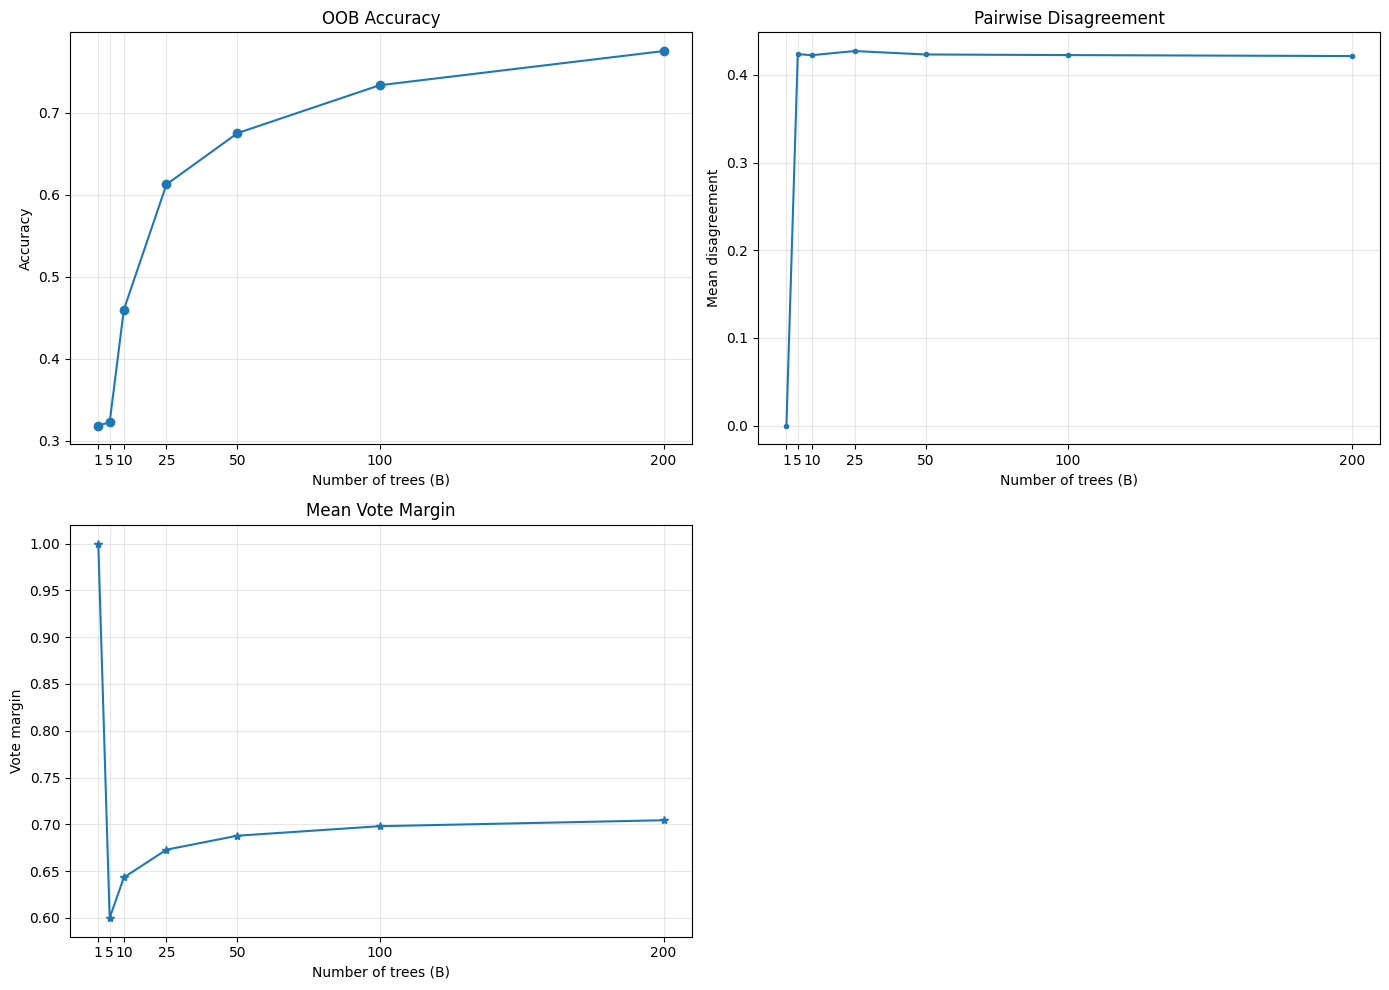

In [15]:
# Plot OOB accuracy, pairwise disagreement and mean vote margin
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

axes[0].plot(results_df["B"], results_df["oob_accuracy"], marker="o")
axes[0].set_title("OOB Accuracy")
axes[0].set_xlabel("Number of trees (B)")
axes[0].set_ylabel("Accuracy")

axes[1].plot(results_df["B"], results_df["avg_pairwise_disagreement"], marker=".")
axes[1].set_title("Pairwise Disagreement")
axes[1].set_xlabel("Number of trees (B)")
axes[1].set_ylabel("Mean disagreement")

axes[2].plot(results_df["B"], results_df["mean_vote_margin"], marker="*")
axes[2].set_title("Mean Vote Margin")
axes[2].set_xlabel("Number of trees (B)")
axes[2].set_ylabel("Vote margin")

for ax in axes:
    ax.set_xticks(BAG_SIZE_VALUES)
    ax.grid(True, alpha=0.3)

axes[3].axis("off")
plt.tight_layout()
plt.savefig("q1c_metrics.png", dpi=200)
plt.show()

In [16]:
# Saving model
final_B = 100

# using first 100 trees from existing ensemble trees
final_bagged_trees = B_models[:final_B]

joblib.dump(final_bagged_trees, 'bagging_model.joblib')

['bagging_model.joblib']

<p style = "margin-top: 50px;">(d) Compare the frozen single tree and the final bagged model on both the clean and masked test sets. Report
accuracy and prediction confidence for both. Find two faces where bagging corrects the tree and two where both
are wrong. Show the tree prediction and bagging vote counts, and use these cases to explain what type of error
bagging can reduce and what type it cannot.</p>

In [17]:
def bagging_confidence(models, X_all):
    votes = np.array([model.predict(X_all) for model in models]).T
    confidence = []

    for row in votes:
        counts = np.bincount(row, minlength=40)
        confidence.append(counts.max() / len(models))

    return np.array(confidence)

In [18]:
# Part D
# Setting rows 24-39 and columns 24-39 to zero, then flatten again
X_test_masked = np.asarray(X_test_split).reshape(-1, 64, 64).copy()
X_test_masked[:, 24:40, 24:40] = 0.0
X_test_masked=X_test_masked.reshape(-1 , 4096)

D_results=[]
for dataset, X_eval in [("clean", X_test_split), ("masked", X_test_masked)]:
    single_pred = chosen_model.predict(X_eval)
    single_accuracy = accuracy_metric(y_test_split, single_pred)
    single_confidence = chosen_model.predict_proba(X_eval).max(axis=1).mean()

    bagged_pred, _ = ensemble_majority_vote(X_eval, np.unique(y_train_split), selected_bagged_models)
    bagged_accuracy = accuracy_metric(y_test_split, bagged_pred)
    bagged_confidence = bagging_confidence(selected_bagged_models, X_eval).mean()

    result = {
        "dataset": dataset,
        "single_tree_accuracy": single_accuracy,
        "single_tree_confidence": single_confidence,
        "bagging_accuracy": bagged_accuracy,
        "bagged_trees_confidence": bagged_confidence,
    }
    D_results.append(result)

D_comparison = pd.DataFrame(D_results)
D_comparison

,dataset,single_tree_accuracy,single_tree_confidence,bagging_accuracy,bagged_trees_confidence
0,clean,0.4625,1.0,0.8500,0.41625
1,masked,0.4625,1.0,0.5375,0.30850


In [19]:
# Let's consider clean test_set for furthur evaluation
y_test_array = y_test_split.to_numpy().ravel()
single_pred = chosen_model.predict(X_test_split)
bagged_pred, predictions = ensemble_majority_vote(X_test_split, np.unique(y_train_split), selected_bagged_models)

# Case 1: Single tree is wrong, but bagging is correct
mask_1 = (single_pred != y_test_array) & (bagged_pred == y_test_array)
correct_indices = np.where(mask_1)[0]
two_correct_indices = correct_indices[:2]

# Case 2: Both single tree and bagging fails
mask_2 = (single_pred != y_test_array) & (bagged_pred != y_test_array)
wrong_indices = np.where(mask_2)[0]
two_wrong_indices = wrong_indices[:2]

# Bagging vote count
combined_indices = np.concatenate((two_correct_indices,two_wrong_indices))
bagged_count = []


# print("Two indices where single tree is wrong but bagged trees are correct :-")
# print(f"Indices = {two_correct_indices}    True Label = {y_test_array[two_correct_indices]}    Single tree predict = {single_pred[two_correct_indices]}    Bagging predict = {bagged_pred[two_correct_indices]}")
# print()
# print("Two indices where both single tree and bagged trees are wrong :-")
# print(f"Indices = {two_wrong_indices}    True Label = {y_test_array[two_wrong_indices]}    Single tree predict = {single_pred[two_wrong_indices]}    Bagging predict = {bagged_pred[two_wrong_indices]}")

for index in combined_indices:
    votes = predictions[: , index]
    counts = np.bincount(votes, minlength=40)
    print("Image index: ", index)
    print("True Label: ", y_test_array[index])
    print("Single tree predict: ", single_pred[index])
    print("Bagging predict: ", bagged_pred[index])
    print("Bagging majority count: ", counts.max())
    print("Non-zero class votes:", {i: int(c) for i,c in enumerate(counts) if c>0})
    print()     

Image index:  2
True Label:  1
Single tree predict:  15
Bagging predict:  1
Bagging majority count:  31
Non-zero class votes: {0: 1, 1: 31, 3: 3, 4: 1, 6: 1, 7: 1, 12: 1, 15: 1, 18: 1, 20: 2, 22: 1, 30: 5, 33: 1}

Image index:  4
True Label:  2
Single tree predict:  3
Bagging predict:  2
Bagging majority count:  13
Non-zero class votes: {1: 1, 2: 13, 3: 1, 4: 3, 5: 1, 7: 4, 12: 1, 14: 1, 15: 1, 19: 1, 20: 1, 21: 1, 22: 3, 24: 3, 25: 2, 27: 2, 28: 3, 31: 1, 33: 1, 34: 2, 37: 2, 38: 2}

Image index:  0
True Label:  0
Single tree predict:  7
Bagging predict:  7
Bagging majority count:  10
Non-zero class votes: {0: 4, 2: 3, 3: 1, 4: 3, 5: 1, 7: 10, 8: 1, 9: 3, 11: 1, 12: 2, 13: 1, 15: 7, 17: 2, 25: 1, 26: 9, 36: 1}

Image index:  13
True Label:  6
Single tree predict:  31
Bagging predict:  35
Bagging majority count:  15
Non-zero class votes: {5: 1, 6: 14, 11: 10, 12: 1, 15: 3, 16: 2, 24: 2, 27: 1, 30: 1, 35: 15}



<h1 style = "margin-top: 50px;">Ques-2</h1>
<h3>Implement SAMME AdaBoost. For K classes, using  formulas:</h3>
<<h4>Clearly specify how the algorithm handles weak learners that perform no better than random guessing in a multiclass setting. Compute class confidence using the normalised weighted voting score, q<sub>k</sub>(x) = S<sub>k</sub>(x) / &sum;<sub>t</sub> &alpha;<sub>t</sub>.</h4>
<p>(a) Before using the face data, create a three class example with at most 10 samples. Log one complete SAMME round: initial sample weights, weak learner predictions, weighted error, αt, and updated normalised weights. Your implementation on the face data must use the same update rule.</p>

In [20]:
# Part A
X_sample = np.array([[0], [1], [2], [3], [4], [5]])
y_sample = np.array(["A", "A", "B", "B", "C", "C"])

sample_weights = np.ones(len(y_sample)) / len(y_sample)
sample_tree = DecisionTreeClassifier(max_depth=1, random_state=RANDOM_SEED)
sample_tree.fit(X_sample, y_sample, sample_weight=sample_weights)

sample_predictions = sample_tree.predict(X_sample)
sample_incorrect = sample_predictions != y_sample
sample_error = float(sample_weights[sample_incorrect].sum())

K_sample = len(np.unique(y_sample))
random_error_limit = 1 - 1 / K_sample

print("One SAMME round on a six-sample, three-class example \n")
print("Initial weights:", sample_weights)
print("True labels:", y_sample)
print("Weak learner predictions:", sample_predictions)
print("Weighted error:", sample_error)

if sample_error < random_error_limit:
    sample_alpha = ( np.log((1 - sample_error) / sample_error) + np.log(K_sample - 1))
    updated_weights = sample_weights.copy()
    updated_weights[sample_incorrect] *= np.exp(sample_alpha)
    updated_weights /= updated_weights.sum()

    print("Alpha:", sample_alpha)
    print("Updated normalised weights:", updated_weights)
    print("Updated weight sum:", updated_weights.sum())
else:
    print(
        "This weak learner is not better than random multiclass prediction; "
        "SAMME must reject it and not update the weights."
    )

One SAMME round on a six-sample, three-class example 

Initial weights: [0.16666667 0.16666667 0.16666667 0.16666667 0.16666667 0.16666667]
True labels: ['A' 'A' 'B' 'B' 'C' 'C']
Weak learner predictions: ['A' 'A' 'B' 'B' 'B' 'B']
Weighted error: 0.3333333333333333
Alpha: 1.3862943611198908
Updated normalised weights: [0.08333333 0.08333333 0.08333333 0.08333333 0.33333333 0.33333333]
Updated weight sum: 1.0


<p style = "margin-top: 50px; font-family: Arial, sans-serif; font-size: 16px;"">(b) On Olivetti Faces, use weak learner depths 1, 2, 3, 4 and 10, 25, 50, 100 rounds. Select depth and rounds using clean validation accuracy only. For the selected model, plot weighted training error, learner weight, maximum sample weight and the total weight carried by the 10 heaviest training images over rounds.</p>

In [21]:

def train_samme(X_all, y_all, max_depth, n_rounds, random_state=RANDOM_SEED):
    """Train a multiclass SAMME ensemble using sample weights."""
    X_all = np.asarray(X_all)
    y_all = np.asarray(y_all).ravel()

    n_samples = len(y_all)
    classes = np.unique(y_all)
    K = len(classes)

    if n_samples == 0 or len(X_all) != n_samples:
        raise ValueError("X and y must contain the same non-zero number of samples.")
    if K < 2:
        raise ValueError("SAMME requires at least two classes.")
    if n_rounds < 1:
        raise ValueError("n_rounds must be at least 1.")

    weights = np.ones(n_samples, dtype=float) / n_samples
    rng = np.random.default_rng(random_state)

    trees = []
    alphas = []
    weighted_errors = []
    max_sample_weights = []
    top10_weight_sums = []

    random_error_limit = 1 - 1 / K

    for t in range(n_rounds):
        tree = DecisionTreeClassifier(max_depth=max_depth,random_state=RANDOM_SEED)
        tree.fit(X_all, y_all, sample_weight=weights)
        predictions = tree.predict(X_all)

        incorrect = predictions != y_all
        weighted_error = float(weights[incorrect].sum())

        # A learner at or above the random-guessing threshold is rejected.
        if weighted_error >= random_error_limit:
            print(
                f"Stopping at round {t + 1}: weighted error "
                f"{weighted_error:.6f} is not below "
                f"{random_error_limit:.6f}."
            )
            break

        # Store diagnostics for the current round before updating weights.
        weighted_errors.append(weighted_error)
        max_sample_weights.append(float(weights.max()))
        top10_weight_sums.append(float(np.sort(weights)[-min(10, n_samples):].sum()))
        trees.append(tree)

        # Avoid an infinite alpha for a perfect learner.
        if weighted_error <= 1e-12:
            alpha = np.log((1 - 1e-12) / 1e-12) + np.log(K - 1)
            alphas.append(float(alpha))
            print(f"Perfect learner reached at round {t + 1}; stopping.")
            break

        alpha = (np.log((1 - weighted_error) / weighted_error) + np.log(K - 1))
        alphas.append(float(alpha))

        # SAMME update: increase only the weights of misclassified samples.
        weights[incorrect] *= np.exp(alpha)
        weights /= weights.sum()

    return {
        "trees": trees,
        "alphas": alphas,
        "weighted_errors": weighted_errors,
        "max_sample_weights": max_sample_weights,
        "top10_weight_sums": top10_weight_sums,
        "final_sample_weights": weights.copy(),
    }

In [22]:
def samme_scores(model, X_all):
    """Return the SAMME class scores for each sample."""

    X_all = np.asarray(X_all)
    trees = model["trees"]
    alphas = model["alphas"]

    if len(trees) == 0:
        raise ValueError("SAMME trained no accepted weak learners.")

    classes = trees[0].classes_
    scores = np.zeros((len(X_all), len(classes)), dtype=float)    # stores score of (each image , class) 

    for tree, alpha in zip(trees, alphas):
        predictions = tree.predict(X_all)

        for i, label in enumerate(predictions):
            scores[i, label] += alpha

    return scores

In [23]:
def predict_samme(model, X_all):
    scores = samme_scores(model, X_all)
    classes = model["trees"][0].classes_
    return classes[np.argmax(scores, axis=1)]

In [24]:
def predict_samme_confidence(model, X_all):
    """Normalised winning weighted vote; this is not a calibrated probability."""
    scores = samme_scores(model, X_all)
    total_alpha = np.sum(model["alphas"])
    if total_alpha <= 0:
        raise ValueError("Total SAMME learner weight must be positive.")
    return scores.max(axis=1) / total_alpha

In [25]:
# Select depth and rounds using validation accuracy only.
BOOST_DEPTHS = [1, 2, 3, 4]
BOOST_ROUNDS = [10, 25, 50, 100]

boosting_results = []
boosting_candidates = {}

for depth in BOOST_DEPTHS:
    for rounds in BOOST_ROUNDS:
        model = train_samme(X_train_split, y_train_split, max_depth=depth, n_rounds=rounds, random_state=RANDOM_SEED)
        val_pred = predict_samme(model, X_val_split)
        val_acc = float(np.mean(val_pred == y_val_split.to_numpy().ravel()))

        boosting_candidates[(depth, rounds)] = model
        boosting_results.append({
            "max_depth": depth,
            "rounds_requested": rounds,
            "rounds_trained": len(model["trees"]),
            "validation_accuracy": val_acc,
        })

boosting_results_df = pd.DataFrame(boosting_results)
boosting_results_df

,max_depth,rounds_requested,rounds_trained,validation_accuracy
0,1,10,10,0.0500
1,1,25,25,0.0875
2,1,50,50,0.1750
3,1,100,100,0.1375
4,2,10,10,0.0750
5,2,25,25,0.1750
6,2,50,50,0.1375
7,2,100,100,0.1375
8,3,10,10,0.1750
9,3,25,25,0.2000


In [26]:
# Validation accuracy is the only selection metric; ties keep the first grid setting.
best_row = max(
    boosting_results,
    key=lambda row: row["validation_accuracy"]
)
MAX_DEPTH_GRID = int(best_row["max_depth"])
BOOSTING_ROUNDS = int(best_row["rounds_requested"])
boosting_model = boosting_candidates[(MAX_DEPTH_GRID, BOOSTING_ROUNDS)]

print(
    f"Selected SAMME model: max_depth={MAX_DEPTH_GRID}, "
    f"rounds requested={BOOSTING_ROUNDS}, "
    f"rounds trained={len(boosting_model['trees'])}, "
    f"validation accuracy={best_row['validation_accuracy']:.4f}"
)

Selected SAMME model: max_depth=4, rounds requested=25, rounds trained=25, validation accuracy=0.4625


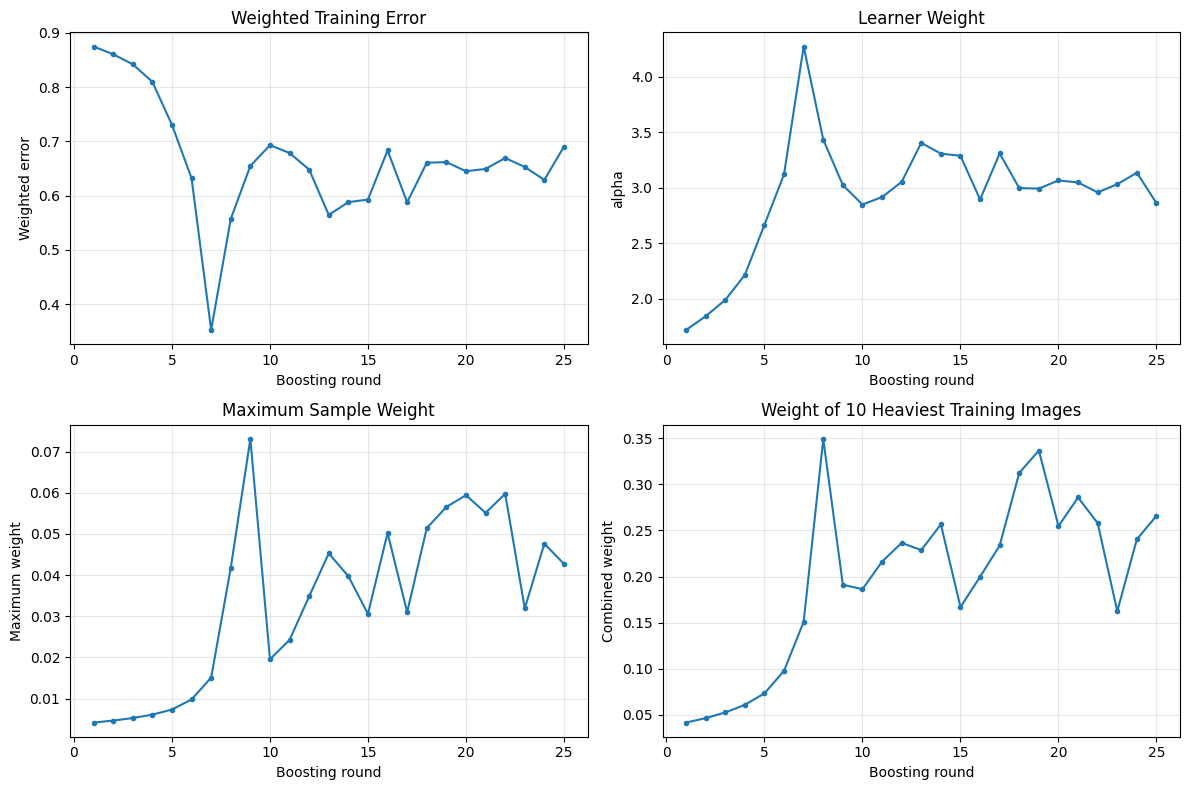

In [27]:
# Plot all four required diagnostics for the selected boosting model.
round_numbers = np.arange(1, len(boosting_model["trees"]) + 1)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
plots = [
    (boosting_model["weighted_errors"], "Weighted Training Error", "Weighted error"),
    (boosting_model["alphas"], "Learner Weight", r"alpha"),
    (boosting_model["max_sample_weights"], "Maximum Sample Weight", "Maximum weight"),
    (boosting_model["top10_weight_sums"], "Weight of 10 Heaviest Training Images", "Combined weight"),
]

for ax, (values, title, ylabel) in zip(axes.flat, plots):
    ax.plot(np.arange(1, len(values) + 1), values, marker=".")
    ax.set_title(title)
    ax.set_xlabel("Boosting round")
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

<p style = "margin-top: 50px; font-family: Arial, sans-serif; font-size: 16px;">(c) Compare boosting and bagging using 25, 50 and 100 learners. Report train, validation and clean test accuracy and training time. Also inspect one training face that receives a very large boosting weight and use its prediction history to explain why boosting repeatedly returns attention to that sample.</p>

In [28]:
# Part C
comparison_results = []
bagged_models_by_B = {}
boosted_models_by_B = {}
classes = np.unique(y_train_split)

for B in [25, 50, 100]:
    # Bagging: train a fresh ensemble and measure actual training time.
    start = perf_counter()
    bagged_trees = []
    rng_bagging = np.random.default_rng(RANDOM_SEED)
    
    X_train_np = np.asarray(X_train_split)
    y_train_np = np.asarray(y_train_split).ravel()
    n_train = len(X_train_np)
    
    for b in range(B):
        bootstrap_indices = rng_bagging.integers(0, n_train, size=n_train)
        tree = DecisionTreeClassifier(max_depth=chosen_depth, min_samples_leaf=chosen_leaf, random_state=RANDOM_SEED)
        tree.fit(X_train_np[bootstrap_indices], y_train_np[bootstrap_indices])
        bagged_trees.append(tree)
    
    bagging_time = perf_counter() - start
    bagged_models_by_B[B] = bagged_trees

    # Boosting uses the selected depth from Q2(b).
    start = perf_counter()
    boosted_model = train_samme(X_train_split, y_train_split, max_depth=MAX_DEPTH_GRID, n_rounds=B, random_state=RANDOM_SEED)
    boosting_time = perf_counter() - start
    boosted_models_by_B[B] = boosted_model

    for model_name, model, train_time in [("Bagging", bagged_trees, bagging_time), ("SAMME", boosted_model, boosting_time)]:
        if model_name == "Bagging":
            train_pred, _ = ensemble_majority_vote(X_train_split, classes, model)
            val_pred, _ = ensemble_majority_vote(X_val_split, classes, model)
            test_pred, _ = ensemble_majority_vote(X_test_split, classes, model)
            n_learners = len(model)
        else:
            train_pred = predict_samme(model, X_train_split)
            val_pred = predict_samme(model, X_val_split)
            test_pred = predict_samme(model, X_test_split)
            n_learners = len(model["trees"])

        comparison_results.append({
            "model": model_name,
            "learners_requested": B,
            "learners_trained": n_learners,
            "train_accuracy": float(np.mean(train_pred == y_train_split.to_numpy().ravel())),
            "validation_accuracy": float(np.mean(val_pred == y_val_split.to_numpy().ravel())),
            "clean_test_accuracy": float(np.mean(test_pred == y_test_split.to_numpy().ravel())),
            "training_time_seconds": train_time,
        })

comparison_df = pd.DataFrame(comparison_results)
comparison_df

,model,learners_requested,learners_trained,train_accuracy,validation_accuracy,clean_test_accuracy,training_time_seconds
0,Bagging,25,25,1.000000,0.8625,0.8625,34.128337
1,SAMME,25,25,0.820833,0.4625,0.3500,9.663847
2,Bagging,50,50,1.000000,0.8875,0.8500,67.163166
3,SAMME,50,50,0.925000,0.4625,0.4125,19.305385
4,Bagging,100,100,1.000000,0.8625,0.8750,137.796266
5,SAMME,100,100,0.954167,0.4125,0.3625,39.352593


Training image index: 142
True identity: 23
Final sample weight: 0.0603108799492424
Initial sample weight: 0.004166666666666667
Rounds misclassified: 23 of 25
Prediction history: [ 0  1  2  3  9  4 23 37  2  3 13 22  4 38 20  1 28 23 25  4 14 15 20  3
 28]


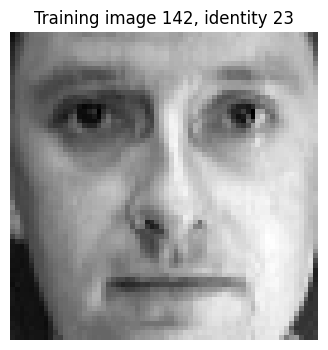

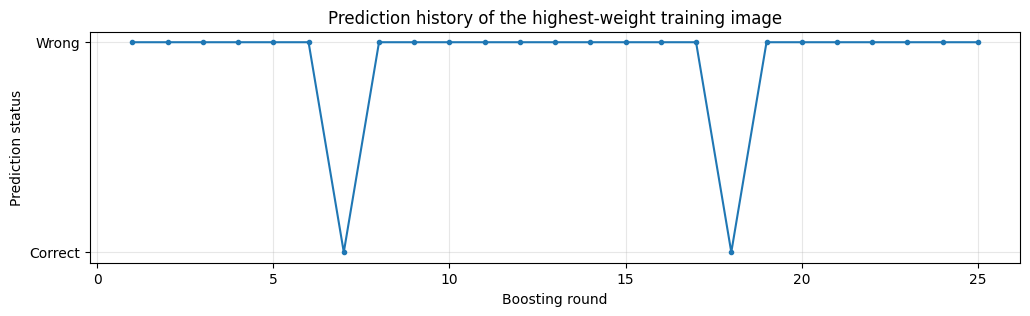

In [29]:
# Inspect the training image with the largest final SAMME weight.
final_weights = boosting_model["final_sample_weights"]
hard_index = int(np.argmax(final_weights))

hard_history = np.array([
    tree.predict(X_train_split[hard_index:hard_index + 1])[0]
    for tree in boosting_model["trees"]
])

hard_wrong = hard_history != np.asarray(y_train_split).ravel()[hard_index]

print("Training image index:", hard_index)
print("True identity:", np.asarray(y_train_split).ravel()[hard_index])
print("Final sample weight:", final_weights[hard_index])
print("Initial sample weight:", 1 / len(y_train_split))
print("Rounds misclassified:", int(hard_wrong.sum()), "of", len(hard_wrong))
print("Prediction history:", hard_history)

plt.figure(figsize=(4, 4))
plt.imshow(X_train_split.iloc[hard_index].to_numpy().reshape(64, 64), cmap="gray")
plt.title(
    f"Training image {hard_index}, identity "
    f"{np.asarray(y_train_split).ravel()[hard_index]}"
)
plt.axis("off")
plt.show()

plt.figure(figsize=(12, 3))
plt.plot(
    np.arange(1, len(hard_history) + 1),
    hard_wrong.astype(int),
    marker="."
)
plt.yticks([0, 1], ["Correct", "Wrong"])
plt.xlabel("Boosting round")
plt.ylabel("Prediction status")
plt.title("Prediction history of the highest-weight training image")
plt.grid(True, alpha=0.3)
plt.show()

In [39]:
# Saving model
joblib.dump(boosting_model, 'boostingModel.joblib')

# Save configuration metadata for reproducibility
config = {
    "baseline_max_depth": None,
    "baseline_min_samples_leaf": 1,
    "bagging_max_depth": None,
    "bagging_min_samples_leaf": 1,
    "bagging_n_estimators": 50,
    "boosting_max_depth": 4,
    "boosting_n_rounds": 25,
    "random_seed": 26005
}

joblib.dump(config, "model_config.joblib")

['model_config.joblib']

<p style="margin-top:50px; font-family: Arial, sans-serif; font-size: 16px;">(d) Keep the best-performing boosting model fixed and compare the single decision tree, bagging ensemble, and boosting ensemble on both clean and masked test data. Record the classification accuracy and average winning-class confidence for each model. Identify a test face where bagging and boosting behave differently after masking, and discuss how tree prediction disagreement and boosting's emphasis on misclassified samples may explain the observed difference.</p>

In [31]:
# Part D
# Build the masked test set if it has not already been created in Q1.
X_masked_test = np.asarray(X_test_split).reshape(-1, 64, 64).copy()
X_masked_test[:, 24:40, 24:40] = 0
X_masked_test = X_masked_test.reshape(-1, 4096)

comparison_rows = []
predictions_by_split = {}

for dataset, X_eval in [("clean", X_test_split), ("masked", X_masked_test)]:
    # Single baseline model
    single_pred = chosen_model.predict(X_eval)
    single_accuracy = accuracy_metric(y_test_split, single_pred)
    single_conf = chosen_model.predict_proba(X_eval).max(axis=1)

    # Frozen final bagged model from Q1
    bagged_pred, _ = ensemble_majority_vote(X_eval, np.unique(y_train_split), selected_bagged_models)
    bagged_accuracy = accuracy_metric(y_test_split, bagged_pred)
    bagged_conf = bagging_confidence(selected_bagged_models, X_eval)

    # Frozen selected SAMME model from Q2(b)
    boost_pred = predict_samme(boosting_model, X_eval)
    boost_accuracy = accuracy_metric(y_test_split, boost_pred)
    boost_conf = predict_samme_confidence(boosting_model, X_eval)

    predictions_by_split[dataset] = {
        "tree_pred": single_pred,
        "bag_pred": bagged_pred,
        "boost_pred": boost_pred,
        "tree_conf": single_conf,
        "bag_conf": bagged_conf,
        "boost_conf": boost_conf,
    }

    comparison_rows.extend([
        {
            "dataset": dataset,
            "model": "Single tree",
            "accuracy": single_accuracy,
            "mean_winning_vote_or_probability": float(np.mean(single_conf)),
        },
        {
            "dataset": dataset,
            "model": "Bagging",
            "accuracy": bagged_accuracy,
            "mean_winning_vote_or_probability": float(np.mean(bagged_conf)),
        },
        {
            "dataset": dataset,
            "model": "SAMME boost",
            "accuracy": boost_accuracy,
            "mean_winning_vote_or_probability": float(np.mean(boost_conf)),
        },
    ])

q2d_results_df = pd.DataFrame(comparison_rows)
q2d_results_df

,dataset,model,accuracy,mean_winning_vote_or_probability
0,clean,Single tree,0.4625,1.000000
1,clean,Bagging,0.8500,0.416250
2,clean,SAMME boost,0.3500,0.138177
3,masked,Single tree,0.4625,1.000000
4,masked,Bagging,0.5375,0.308500
5,masked,SAMME boost,0.2625,0.142213



Example with different bagging/boosting response to masking
Test index: 0
True identity: 0
Bagging clean prediction: 7
Bagging masked prediction: 13
Bagging clean and masked winning vote fraction: 0.2     0.18
Boosting clean prediction: 15
Boosting masked prediction: 15
Boosting clean/masked normalised weighted vote: 0.14332592573767358 0.14332592573767358
Bagging votes (clean): {0: 4, 2: 3, 3: 1, 4: 3, 5: 1, 7: 10, 8: 1, 9: 3, 11: 1, 12: 2, 13: 1, 15: 7, 17: 2, 25: 1, 26: 9, 36: 1}
Bagging votes (masked): {0: 3, 2: 1, 3: 2, 4: 2, 5: 1, 7: 8, 9: 3, 13: 9, 15: 2, 16: 1, 20: 1, 25: 1, 26: 8, 33: 4, 35: 1, 36: 1, 38: 1, 39: 1}


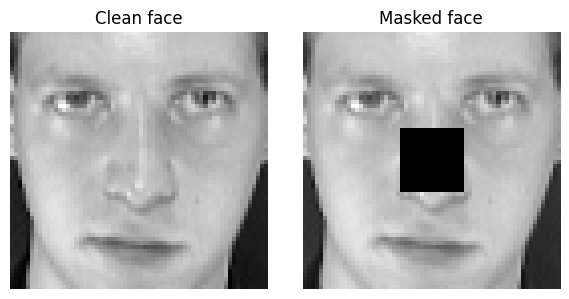

In [32]:
# Find a face where bagging and boosting respond differently to masking.
clean = predictions_by_split["clean"]
masked = predictions_by_split["masked"]

bag_changed = clean["bag_pred"] != masked["bag_pred"]
boost_changed = clean["boost_pred"] != masked["boost_pred"]

different_response = np.flatnonzero(bag_changed != boost_changed)

if len(different_response) > 0:
    idx = int(different_response[0])

    print("\nExample with different bagging/boosting response to masking")
    print("Test index:", idx)
    print("True identity:", int(y_test_split.iloc[idx].item()))
    print("Bagging clean prediction:", clean["bag_pred"][idx])
    print("Bagging masked prediction:", masked["bag_pred"][idx])
    print("Bagging clean and masked winning vote fraction:", clean["bag_conf"][idx], "   ",masked["bag_conf"][idx])
    print("Boosting clean prediction:", clean["boost_pred"][idx])
    print("Boosting masked prediction:", masked["boost_pred"][idx])
    print("Boosting clean/masked normalised weighted vote:", clean["boost_conf"][idx], masked["boost_conf"][idx])

    # Show class-wise bagging vote counts for the selected image.
    _, bag_clean_votes = ensemble_majority_vote(X_test_split[idx:idx + 1], np.unique(y_train_split),selected_bagged_models)

    _, bag_masked_votes = ensemble_majority_vote(X_masked_test[idx:idx + 1], np.unique(y_train_split), selected_bagged_models)
    print("Bagging votes (clean):",
          {int(c): int(np.sum(bag_clean_votes == c))
           for c in np.unique(bag_clean_votes)})
    print("Bagging votes (masked):",
          {int(c): int(np.sum(bag_masked_votes == c))
           for c in np.unique(bag_masked_votes)})

    fig, axes = plt.subplots(1, 2, figsize=(6, 3))
    axes[0].imshow(np.asarray(X_test_split)[idx].reshape(64, 64), cmap="gray")
    axes[0].set_title("Clean face")
    axes[0].axis("off")
    axes[1].imshow(np.asarray(X_masked_test)[idx].reshape(64, 64), cmap="gray")
    axes[1].set_title("Masked face")
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()
else:
    print(
        "No test image was found where the models' prediction response differs. "
        "Inspect the full clean/masked prediction arrays and report this honestly."
    )


<h1 style="margin-top: 50px;">Question 3</h1>
<h3>Quantitative Analysis of Bias and Variance</h3>
<h4>
Keep the clean test set unchanged throughout the experiment. Generate 30 bootstrap training sets by independently sampling, with replacement, six images from the six original training images of each identity. Train the previously selected single decision tree, bagging ensemble, and boosting ensemble on every resampled dataset without performing further hyperparameter tuning. For each test image x<sub>i</sub>, let p<sub>r</sub>(x<sub>i</sub>) denote the predicted class-probability vector in repetition r, p&#772;(x<sub>i</sub>) its average across all repetitions, and e<sub>i</sub> the corresponding one-hot target vector. For boosting, obtain the prediction vector using the normalised weighted voting scheme. Using the provided formulas, calculate the bias and variance measures for all three models.
</h4>

In [33]:
N_REPEATS_Q3 = 30
NUM_JOBS_Q3 = 4

X_train_q3 = np.asarray(X_train_split)
y_train_q3 = np.asarray(y_train_split).ravel().astype(int)
X_test_q3 = np.asarray(X_test_split)
y_test_q3 = np.asarray(y_test_split).ravel().astype(int)
Q3_CLASS_LABELS = np.arange(len(np.unique(y_train_q3)))

# Reuse the masked test set already created in Q1/Q2.
X_masked_test_q3 = np.asarray(X_test_masked).reshape(-1, 4096)

# Making 30 stratified bootstrap datasets: sample six times with replacement from each identity's original six training faces.
rng_q3 = np.random.default_rng(RANDOM_SEED)
resampled_train_sets_q3 = []
for r in range(N_REPEATS_Q3):
    sampled_rows = []
    for identity in Q3_CLASS_LABELS:
        identity_rows = np.flatnonzero(y_train_q3 == identity)
        sampled_rows.extend(rng_q3.choice(identity_rows, size=6, replace=True))
    sampled_rows = np.asarray(sampled_rows, dtype=int)
    resampled_train_sets_q3.append((X_train_q3[sampled_rows], y_train_q3[sampled_rows]))

print("Resampled training sets:", len(resampled_train_sets_q3))
print("Shape of each resampled X:", resampled_train_sets_q3[0][0].shape)
print("Parallel workers:", NUM_JOBS_Q3)

Resampled training sets: 30
Shape of each resampled X: (240, 4096)
Parallel workers: 4


<p style = "margin-top:50px; font-family: Arial, sans-serif; font-size: 16px;">(a) Report measured bias squared and variance for the selected single tree, bagging and boosting models. Also report
the mean and standard deviation of test accuracy across the 30 refits.</p>

In [34]:
def measure_bias_variance_q3(class_vectors_by_repeat, y_true):
    """Compute squared bias and variance from repeated class-vote vectors."""
    mean_vectors = class_vectors_by_repeat.mean(axis=0)
    one_hot = np.eye(len(Q3_CLASS_LABELS))[np.asarray(y_true, dtype=int)]
    bias_squared = np.mean(np.sum((mean_vectors - one_hot) ** 2, axis=1))
    variance = np.mean(np.sum(
        (class_vectors_by_repeat - mean_vectors[None, :, :]) ** 2, axis=2
    ))
    repeated_predictions = np.argmax(class_vectors_by_repeat, axis=2)
    repeated_accuracy = np.mean(repeated_predictions == np.asarray(y_true)[None, :], axis=1)
    return {
        "Bias squared": float(bias_squared),
        "Variance": float(variance),
        "Mean test accuracy (%)": float(repeated_accuracy.mean() * 100),
        "Std test accuracy (percentage points)": float(repeated_accuracy.std(ddof=1) * 100),
    }


# Part A
BAGGING_SIZE_Q3A = len(selected_bagged_models)

def q3a_one_repetition(r, X_r, y_r):
    seed = RANDOM_SEED + r

    # Selected Q1 single tree: keep the selected hyperparameters fixed.
    tree_r = DecisionTreeClassifier(max_depth=chosen_depth, min_samples_leaf=chosen_leaf, random_state=seed)
    tree_r.fit(X_r, y_r)
    tree_prob = tree_r.predict_proba(X_test_q3)
    tree_vectors = np.zeros((len(X_test_q3), len(Q3_CLASS_LABELS)))
    for j, label in enumerate(tree_r.classes_):
        tree_vectors[:, int(label)] = tree_prob[:, j]

    # Refitting a bagged model with the same number of trees as the selected Q1 model.
    rng_local = np.random.default_rng(seed)
    bagged_trees_r = []
    for _ in range(BAGGING_SIZE_Q3A):
        boot_idx = rng_local.choice(len(y_r), size=len(y_r), replace=True)
        tree_seed = RANDOM_SEED
        tree = DecisionTreeClassifier(max_depth=chosen_depth, min_samples_leaf=chosen_leaf, random_state=tree_seed)
        tree.fit(X_r[boot_idx], y_r[boot_idx])
        bagged_trees_r.append(tree)

    # Reusing vote_majority's returned individual tree predictions to form class vectors.
    _, bag_tree_predictions = ensemble_majority_vote(X_test_q3, Q3_CLASS_LABELS, bagged_trees_r)
    bag_vectors = np.zeros((len(X_test_q3), len(Q3_CLASS_LABELS)))
    for i in range(len(X_test_q3)):
        bag_vectors[i] = np.bincount(np.asarray(bag_tree_predictions[:, i], dtype=int), minlength=len(Q3_CLASS_LABELS)) / len(bagged_trees_r)

    # Refiting the selected SAMME settings
    boost_r = train_samme(X_r, y_r, max_depth=MAX_DEPTH_GRID, n_rounds=BOOSTING_ROUNDS, random_state=seed)
    boost_scores = samme_scores(boost_r, X_test_q3)
    total_alpha = np.sum(boost_r["alphas"])
    if total_alpha <= 0:
        raise ValueError("SAMME produced no positive total learner weight in repetition " + str(r))
    boost_vectors = np.zeros((len(X_test_q3), len(Q3_CLASS_LABELS)))
    boost_classes = boost_r["trees"][0].classes_
    for j, label in enumerate(boost_classes):
        boost_vectors[:, int(label)] = boost_scores[:, j] / total_alpha

    return r, tree_vectors, bag_vectors, boost_vectors


q3a_runs = Parallel(n_jobs=NUM_JOBS_Q3, backend="loky", verbose=10)(
    delayed(q3a_one_repetition)(r, X_r, y_r)
    for r, (X_r, y_r) in enumerate(resampled_train_sets_q3)
)
q3a_runs.sort(key=lambda row: row[0])

tree_vectors_q3a = np.stack([row[1] for row in q3a_runs])
bag_vectors_q3a = np.stack([row[2] for row in q3a_runs])
boost_vectors_q3a = np.stack([row[3] for row in q3a_runs])

q3a_results = pd.DataFrame({
    "Selected single tree": measure_bias_variance_q3(tree_vectors_q3a, y_test_q3),
    f"Selected bagging (B={BAGGING_SIZE_Q3A})": measure_bias_variance_q3(bag_vectors_q3a, y_test_q3),
    f"Selected SAMME (depth={MAX_DEPTH_GRID}, rounds={BOOSTING_ROUNDS})": measure_bias_variance_q3(boost_vectors_q3a, y_test_q3),
}).T

print(q3a_results.round(4))

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:  3.6min
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:  5.4min
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:  9.0min
[Parallel(n_jobs=4)]: Done  27 out of  30 | elapsed: 12.6min remaining:  1.4min
[Parallel(n_jobs=4)]: Done  30 out of  30 | elapsed: 14.2min finished


                                     Bias squared  Variance  \
Selected single tree                       0.3983    0.6675   
Selected bagging (B=50)                    0.5107    0.0350   
Selected SAMME (depth=4, rounds=25)        0.8905    0.0294   

                                     Mean test accuracy (%)  \
Selected single tree                                46.7083   
Selected bagging (B=50)                             75.9167   
Selected SAMME (depth=4, rounds=25)                 21.6250   

                                     Std test accuracy (percentage points)  
Selected single tree                                                4.5306  
Selected bagging (B=50)                                             4.0061  
Selected SAMME (depth=4, rounds=25)                                 7.6996  


<p style = "margin-top:50px; font-family: Arial, sans-serif; font-size: 16px;">(b) Repeat the calculation for single trees at one shallow depth, the selected depth and one much deeper depth. At
the same three depths build 100 tree bagged ensembles. Quantify how depth changes bias and variance, and how
much variance bagging removes at each depth.</p>

In [35]:
# Part- B
"""Comparing a shallow, selected, and deeper tree; build 100-tree bagging
ensembles at each depth. This part is also parallelised on four workers."""

if chosen_depth is None:
    DEPTHS_Q3B = [2, 8, None]
elif chosen_depth == 2:
    DEPTHS_Q3B = [1, 2, None]
else:
    shallow_depth = 2 if chosen_depth > 2 else 1
    DEPTHS_Q3B = list(dict.fromkeys([shallow_depth, chosen_depth, None]))

BAGGING_SIZE_Q3B = 100
print("Depths compared:", DEPTHS_Q3B)
print("Trees per ensemble:", BAGGING_SIZE_Q3B)


def q3b_one_repetition(depth, r, X_r, y_r):
    seed = RANDOM_SEED + r

    single = DecisionTreeClassifier(
        max_depth=depth, min_samples_leaf=chosen_leaf, random_state=seed
    )
    single.fit(X_r, y_r)
    single_prob = single.predict_proba(X_test_q3)
    single_vectors = np.zeros((len(X_test_q3), len(Q3_CLASS_LABELS)))
    for j, label in enumerate(single.classes_):
        single_vectors[:, int(label)] = single_prob[:, j]

    # Inline fitting of the 100 bootstrap trees; use the existing vote_majority function.
    rng_local = np.random.default_rng(seed + (0 if depth is None else int(depth) * 1000))
    bagged_trees = []
    for _ in range(BAGGING_SIZE_Q3B):
        boot_idx = rng_local.choice(len(y_r), size=len(y_r), replace=True)
        tree_seed = int(rng_local.integers(0, 2**31 - 1))
        tree = DecisionTreeClassifier(
            max_depth=depth, min_samples_leaf=chosen_leaf, random_state=tree_seed
        )
        tree.fit(X_r[boot_idx], y_r[boot_idx])
        bagged_trees.append(tree)

    _, tree_predictions = ensemble_majority_vote(X_test_q3, Q3_CLASS_LABELS, bagged_trees)
    bag_vectors = np.zeros((len(X_test_q3), len(Q3_CLASS_LABELS)))
    for i in range(len(X_test_q3)):
        bag_vectors[i] = np.bincount(
            np.asarray(tree_predictions[:, i], dtype=int), minlength=len(Q3_CLASS_LABELS)
        ) / len(bagged_trees)

    # Reuse the notebook's existing pairwise_disagreement function.
    disagreement = pairwise_disagreement(tree_predictions)

    # Leaf occupancy, measured on this repetition's resampled training set.
    single_leaf_ids = single.apply(X_r)
    _, single_leaf_counts = np.unique(single_leaf_ids, return_counts=True)
    single_occupancy = {
        "leaves": len(single_leaf_counts),
        "mean_samples_per_leaf": float(single_leaf_counts.mean()),
        "singleton_leaf_fraction": float(np.mean(single_leaf_counts == 1)),
    }

    all_leaf_counts = []
    all_mean_occupancies = []
    all_singleton_fractions = []
    for tree in bagged_trees:
        _, leaf_counts = np.unique(tree.apply(X_r), return_counts=True)
        all_leaf_counts.append(len(leaf_counts))
        all_mean_occupancies.append(float(leaf_counts.mean()))
        all_singleton_fractions.append(float(np.mean(leaf_counts == 1)))

    bagged_occupancy = {
        "leaves": float(np.mean(all_leaf_counts)),
        "mean_samples_per_leaf": float(np.mean(all_mean_occupancies)),
        "singleton_leaf_fraction": float(np.mean(all_singleton_fractions)),
    }

    single_accuracy = float(np.mean(np.argmax(single_vectors, axis=1) == y_test_q3))
    bag_accuracy = float(np.mean(np.argmax(bag_vectors, axis=1) == y_test_q3))

    return {
        "depth": depth, "repetition": r,
        "single_vectors": single_vectors, "bag_vectors": bag_vectors,
        "single_accuracy": single_accuracy, "bag_accuracy": bag_accuracy,
        "single_occupancy": single_occupancy, "bag_occupancy": bagged_occupancy,
        "disagreement": disagreement,
    }

q3b_jobs = [
    (depth, r, X_r, y_r)
    for depth in DEPTHS_Q3B
    for r, (X_r, y_r) in enumerate(resampled_train_sets_q3)
]
q3b_runs = Parallel(n_jobs=NUM_JOBS_Q3, backend="loky", verbose=10)(
    delayed(q3b_one_repetition)(depth, r, X_r, y_r)
    for depth, r, X_r, y_r in q3b_jobs
)
print("Completed Q3(b) jobs:", len(q3b_runs))

q3b_depth_metrics = {}
q3b_rows = []
q3b_variance_rows = []
for depth in DEPTHS_Q3B:
    group = sorted([row for row in q3b_runs if row["depth"] == depth], key=lambda row: row["repetition"])
    single_vectors_all = np.stack([row["single_vectors"] for row in group])
    bag_vectors_all = np.stack([row["bag_vectors"] for row in group])
    single_metrics = measure_bias_variance_q3(single_vectors_all, y_test_q3)
    bag_metrics = measure_bias_variance_q3(bag_vectors_all, y_test_q3)

    single_acc_mean = np.mean([row["single_accuracy"] for row in group]) * 100
    single_acc_sd = np.std([row["single_accuracy"] for row in group], ddof=1) * 100
    bag_acc_mean = np.mean([row["bag_accuracy"] for row in group]) * 100
    bag_acc_sd = np.std([row["bag_accuracy"] for row in group], ddof=1) * 100
    single_leaves = np.mean([row["single_occupancy"]["leaves"] for row in group])
    single_occ = np.mean([row["single_occupancy"]["mean_samples_per_leaf"] for row in group])
    single_singletons = np.mean([row["single_occupancy"]["singleton_leaf_fraction"] for row in group])
    bag_leaves = np.mean([row["bag_occupancy"]["leaves"] for row in group])
    bag_occ = np.mean([row["bag_occupancy"]["mean_samples_per_leaf"] for row in group])
    bag_singletons = np.mean([row["bag_occupancy"]["singleton_leaf_fraction"] for row in group])
    disagreement = np.mean([row["disagreement"] for row in group])

    q3b_depth_metrics[depth] = {
        "single_metrics": single_metrics, "bag_metrics": bag_metrics,
        "single_accuracy_mean": single_acc_mean, "bag_accuracy_mean": bag_acc_mean,
        "disagreement": disagreement,
    }
    q3b_rows.extend([
        {"Depth": str(depth), "Model": "Single tree",
         "Bias squared": single_metrics["Bias squared"], "Variance": single_metrics["Variance"],
         "Mean accuracy (%)": single_acc_mean, "Accuracy SD (pp)": single_acc_sd,
         "Mean leaves": single_leaves, "Mean samples/leaf": single_occ,
         "Singleton leaf fraction": single_singletons, "Pairwise disagreement": np.nan},
        {"Depth": str(depth), "Model": "Bagging (B=100)",
         "Bias squared": bag_metrics["Bias squared"], "Variance": bag_metrics["Variance"],
         "Mean accuracy (%)": bag_acc_mean, "Accuracy SD (pp)": bag_acc_sd,
         "Mean leaves": bag_leaves, "Mean samples/leaf": bag_occ,
         "Singleton leaf fraction": bag_singletons, "Pairwise disagreement": disagreement},
    ])
    single_var = single_metrics["Variance"]
    bag_var = bag_metrics["Variance"]
    q3b_variance_rows.append({
        "Depth": str(depth), "Single-tree variance": single_var, "Bagged variance": bag_var,
        "Variance reduction (%)": (100 * (single_var - bag_var) / single_var if single_var > 0 else np.nan),
        "Single-tree accuracy (%)": single_acc_mean, "Bagged accuracy (%)": bag_acc_mean,
        "Accuracy improvement (pp)": bag_acc_mean - single_acc_mean,
    })

q3b_table = pd.DataFrame(q3b_rows)
q3b_variance_comparison = pd.DataFrame(q3b_variance_rows)
print(q3b_table.round(4))
print(q3b_variance_comparison.round(4))


Depths compared: [2, 8, None]
Trees per ensemble: 100


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:   43.5s
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:  1.1min
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:  1.8min
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:  2.2min
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed:  4.2min
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:  6.8min
[Parallel(n_jobs=4)]: Done  53 tasks      | elapsed: 10.7min
[Parallel(n_jobs=4)]: Done  64 tasks      | elapsed: 16.3min
[Parallel(n_jobs=4)]: Done  77 tasks      | elapsed: 27.8min
[Parallel(n_jobs=4)]: Done  90 out of  90 | elapsed: 37.2min finished


Completed Q3(b) jobs: 90
  Depth            Model  Bias squared  Variance  Mean accuracy (%)  \
0     2      Single tree        0.9125    0.0370             6.2083   
1     2  Bagging (B=100)        0.9342    0.0109            12.6250   
2     8      Single tree        0.7867    0.1370            15.4167   
3     8  Bagging (B=100)        0.8171    0.0165            40.7500   
4  None      Single tree        0.3983    0.6675            46.7083   
5  None  Bagging (B=100)        0.5072    0.0261            79.5417   

   Accuracy SD (pp)  Mean leaves  Mean samples/leaf  Singleton leaf fraction  \
0            1.0629       3.0333            79.3333                   0.0000   
1            5.9664       3.1373            77.2533                   0.0093   
2            2.4197       9.2667            26.0040                   0.0000   
3            6.5866      10.7637            22.7337                   0.0388   
4            4.5306      40.0000             6.0000                   0.0000 

<p style = "margin-top: 50px; font-family: Arial, sans-serif; font-size: 16px;">(c) Determine whether the deepest tree is necessarily the depth at which bagging gives the largest improvement
in test accuracy. Your answer must use your measured bias, variance, leaf occupancy and disagreement results
rather than a generic statement about the bias variance tradeoff.</p>

In [36]:
# Part - C
best_improvement_row = q3b_variance_comparison.loc[q3b_variance_comparison["Accuracy improvement (pp)"].idxmax()]
deepest_label = str(DEPTHS_Q3B[-1])
deepest_row = q3b_variance_comparison[q3b_variance_comparison["Depth"] == deepest_label].iloc[0]

print("Depth with the largest measured bagging accuracy improvement:", best_improvement_row["Depth"])
print("Largest accuracy improvement (percentage points):", round(best_improvement_row["Accuracy improvement (pp)"], 4))
print("Deepest tested depth:", deepest_label)
print("Deepest-depth accuracy improvement (percentage points):", round(deepest_row["Accuracy improvement (pp)"], 4))
print("Does the deepest tested tree give the largest improvement?", bool(best_improvement_row["Depth"] == deepest_label))
print("\nUsing q3b_table to compare leaf occupancy and pairwise disagreement and "
      "q3b_variance_comparison to compare variance reduction and accuracy improvement.")

display(q3b_variance_comparison.round(4))



Depth with the largest measured bagging accuracy improvement: None
Largest accuracy improvement (percentage points): 32.8333
Deepest tested depth: None
Deepest-depth accuracy improvement (percentage points): 32.8333
Does the deepest tested tree give the largest improvement? True

Using q3b_table to compare leaf occupancy and pairwise disagreement and q3b_variance_comparison to compare variance reduction and accuracy improvement.


,Depth,Single-tree variance,Bagged variance,Variance reduction (%),Single-tree accuracy (%),Bagged accuracy (%),Accuracy improvement (pp)
0,2,0.0370,0.0109,70.5028,6.2083,12.6250,6.4167
1,8,0.1370,0.0165,87.9649,15.4167,40.7500,25.3333
2,None,0.6675,0.0261,96.0900,46.7083,79.5417,32.8333


<p style = "margin-top: 50px; font-family: Arial, sans-serif; font-size: 16px;">(d) End with one table for the selected single tree, bagging and boosting models containing clean test accuracy,
masked test accuracy, bias squared and variance. Using this table together with your earlier plots, explain which
model is most stable, which is most sensitive to the missing region, and whether the model with the lowest
variance is necessarily the model with the best test accuracy</p>

In [37]:
# Part - D
clean_predictions = predictions_by_split["clean"]
masked_predictions = predictions_by_split["masked"]

q3d_bias_variance = {
    "Single decision tree": measure_bias_variance_q3(tree_vectors_q3a, y_test_q3),
    "Bagging": measure_bias_variance_q3(bag_vectors_q3a, y_test_q3),
    "SAMME boosting": measure_bias_variance_q3(boost_vectors_q3a, y_test_q3),
}
q3d_prediction_keys = {
    "Single decision tree": "tree_pred",
    "Bagging": "bag_pred",
    "SAMME boosting": "boost_pred",
}

q3d_rows = []
for model_name, pred_key in q3d_prediction_keys.items():
    clean_acc = float(np.mean(np.asarray(clean_predictions[pred_key]).ravel() == y_test_q3))
    masked_acc = float(np.mean(np.asarray(masked_predictions[pred_key]).ravel() == y_test_q3))
    metrics = q3d_bias_variance[model_name]
    q3d_rows.append({
        "Model": model_name,
        "Clean test accuracy (%)": 100 * clean_acc,
        "Masked test accuracy (%)": 100 * masked_acc,
        "Accuracy drop (pp)": 100 * (clean_acc - masked_acc),
        "Bias squared": metrics["Bias squared"],
        "Variance": metrics["Variance"],
    })

q3d_final_table = pd.DataFrame(q3d_rows)
display(q3d_final_table.round(4))

most_stable_q3 = q3d_final_table.loc[q3d_final_table["Variance"].idxmin(), "Model"]
most_mask_sensitive_q3 = q3d_final_table.loc[q3d_final_table["Accuracy drop (pp)"].idxmax(), "Model"]
best_clean_q3 = q3d_final_table.loc[q3d_final_table["Clean test accuracy (%)"].idxmax(), "Model"]
print("Lowest measured variance (most stable across resamples):", most_stable_q3)
print("Largest clean-to-masked accuracy drop (most mask-sensitive):", most_mask_sensitive_q3)
print("Highest clean test accuracy:", best_clean_q3)
print("The lowest-variance model is not necessarily the highest-accuracy model; compare both columns above.")

,Model,Clean test accuracy (%),Masked test accuracy (%),Accuracy drop (pp),Bias squared,Variance
0,Single decision tree,46.25,46.25,0.00,0.3983,0.6675
1,Bagging,85.00,53.75,31.25,0.5107,0.0350
2,SAMME boosting,35.00,26.25,8.75,0.8905,0.0294


Lowest measured variance (most stable across resamples): SAMME boosting
Largest clean-to-masked accuracy drop (most mask-sensitive): Bagging
Highest clean test accuracy: Bagging
The lowest-variance model is not necessarily the highest-accuracy model; compare both columns above.


In [38]:
%pip freeze > requirements.txt

Note: you may need to restart the kernel to use updated packages.
